# Dataset Olist 2016-2018 (Kaggle)

Acessar o link abaixo e fazer download do zip que contém 9 arquivos de formato csv

https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

## Contexto da atividade

Você trabalha como analista de dados em um marketplace de e-commerce brasileiro. A empresa deseja compreender melhor suas operações para apoiar decisões estratégicas relacionadas a vendas, logística, experiência do cliente e desempenho de vendedores.

Para isso, você recebeu um conjunto de dados contendo informações sobre pedidos, clientes, vendedores, produtos, pagamentos, avaliações e entregas. Esses dados correspondem às operações de um marketplace real da empresa Olist.

Seu objetivo é explorar os dados e produzir análises que permitam responder perguntas de negócio relevantes. As respostas devem ser acompanhadas de visualizações e interpretações que ajudem a entender o comportamento do sistema.

O dataset está dividido em vários arquivos CSV, cada um representando uma parte do sistema (pedidos, clientes, pagamentos, etc.). Em muitas análises será necessário combinar informações de diferentes arquivos.

## Descrição do dataset (Kaggle)

Este conjunto de dados contém informações sobre o cliente e sua localização. Use-o para identificar clientes únicos no conjunto de dados de pedidos e para encontrar o local de entrega dos pedidos.

Em nosso sistema, cada pedido é atribuído a um customer_id exclusivo. Isso significa que o mesmo cliente receberá IDs diferentes para pedidos diferentes. O objetivo de ter um customer_unique_id no conjunto de dados é permitir identificar os clientes que fizeram recompras na loja. Caso contrário, você descobriria que cada pedido tinha um cliente diferente associado.

Consulte o esquema de dados:

**Data schema**: Mostra como os dados estão organizados nas bases operacionais: quais tabelas existem e como elas se relacionam por meio de chaves (por exemplo order_id, product_id). Funciona como um mapa que permite entender onde cada tipo de informação está armazenado.

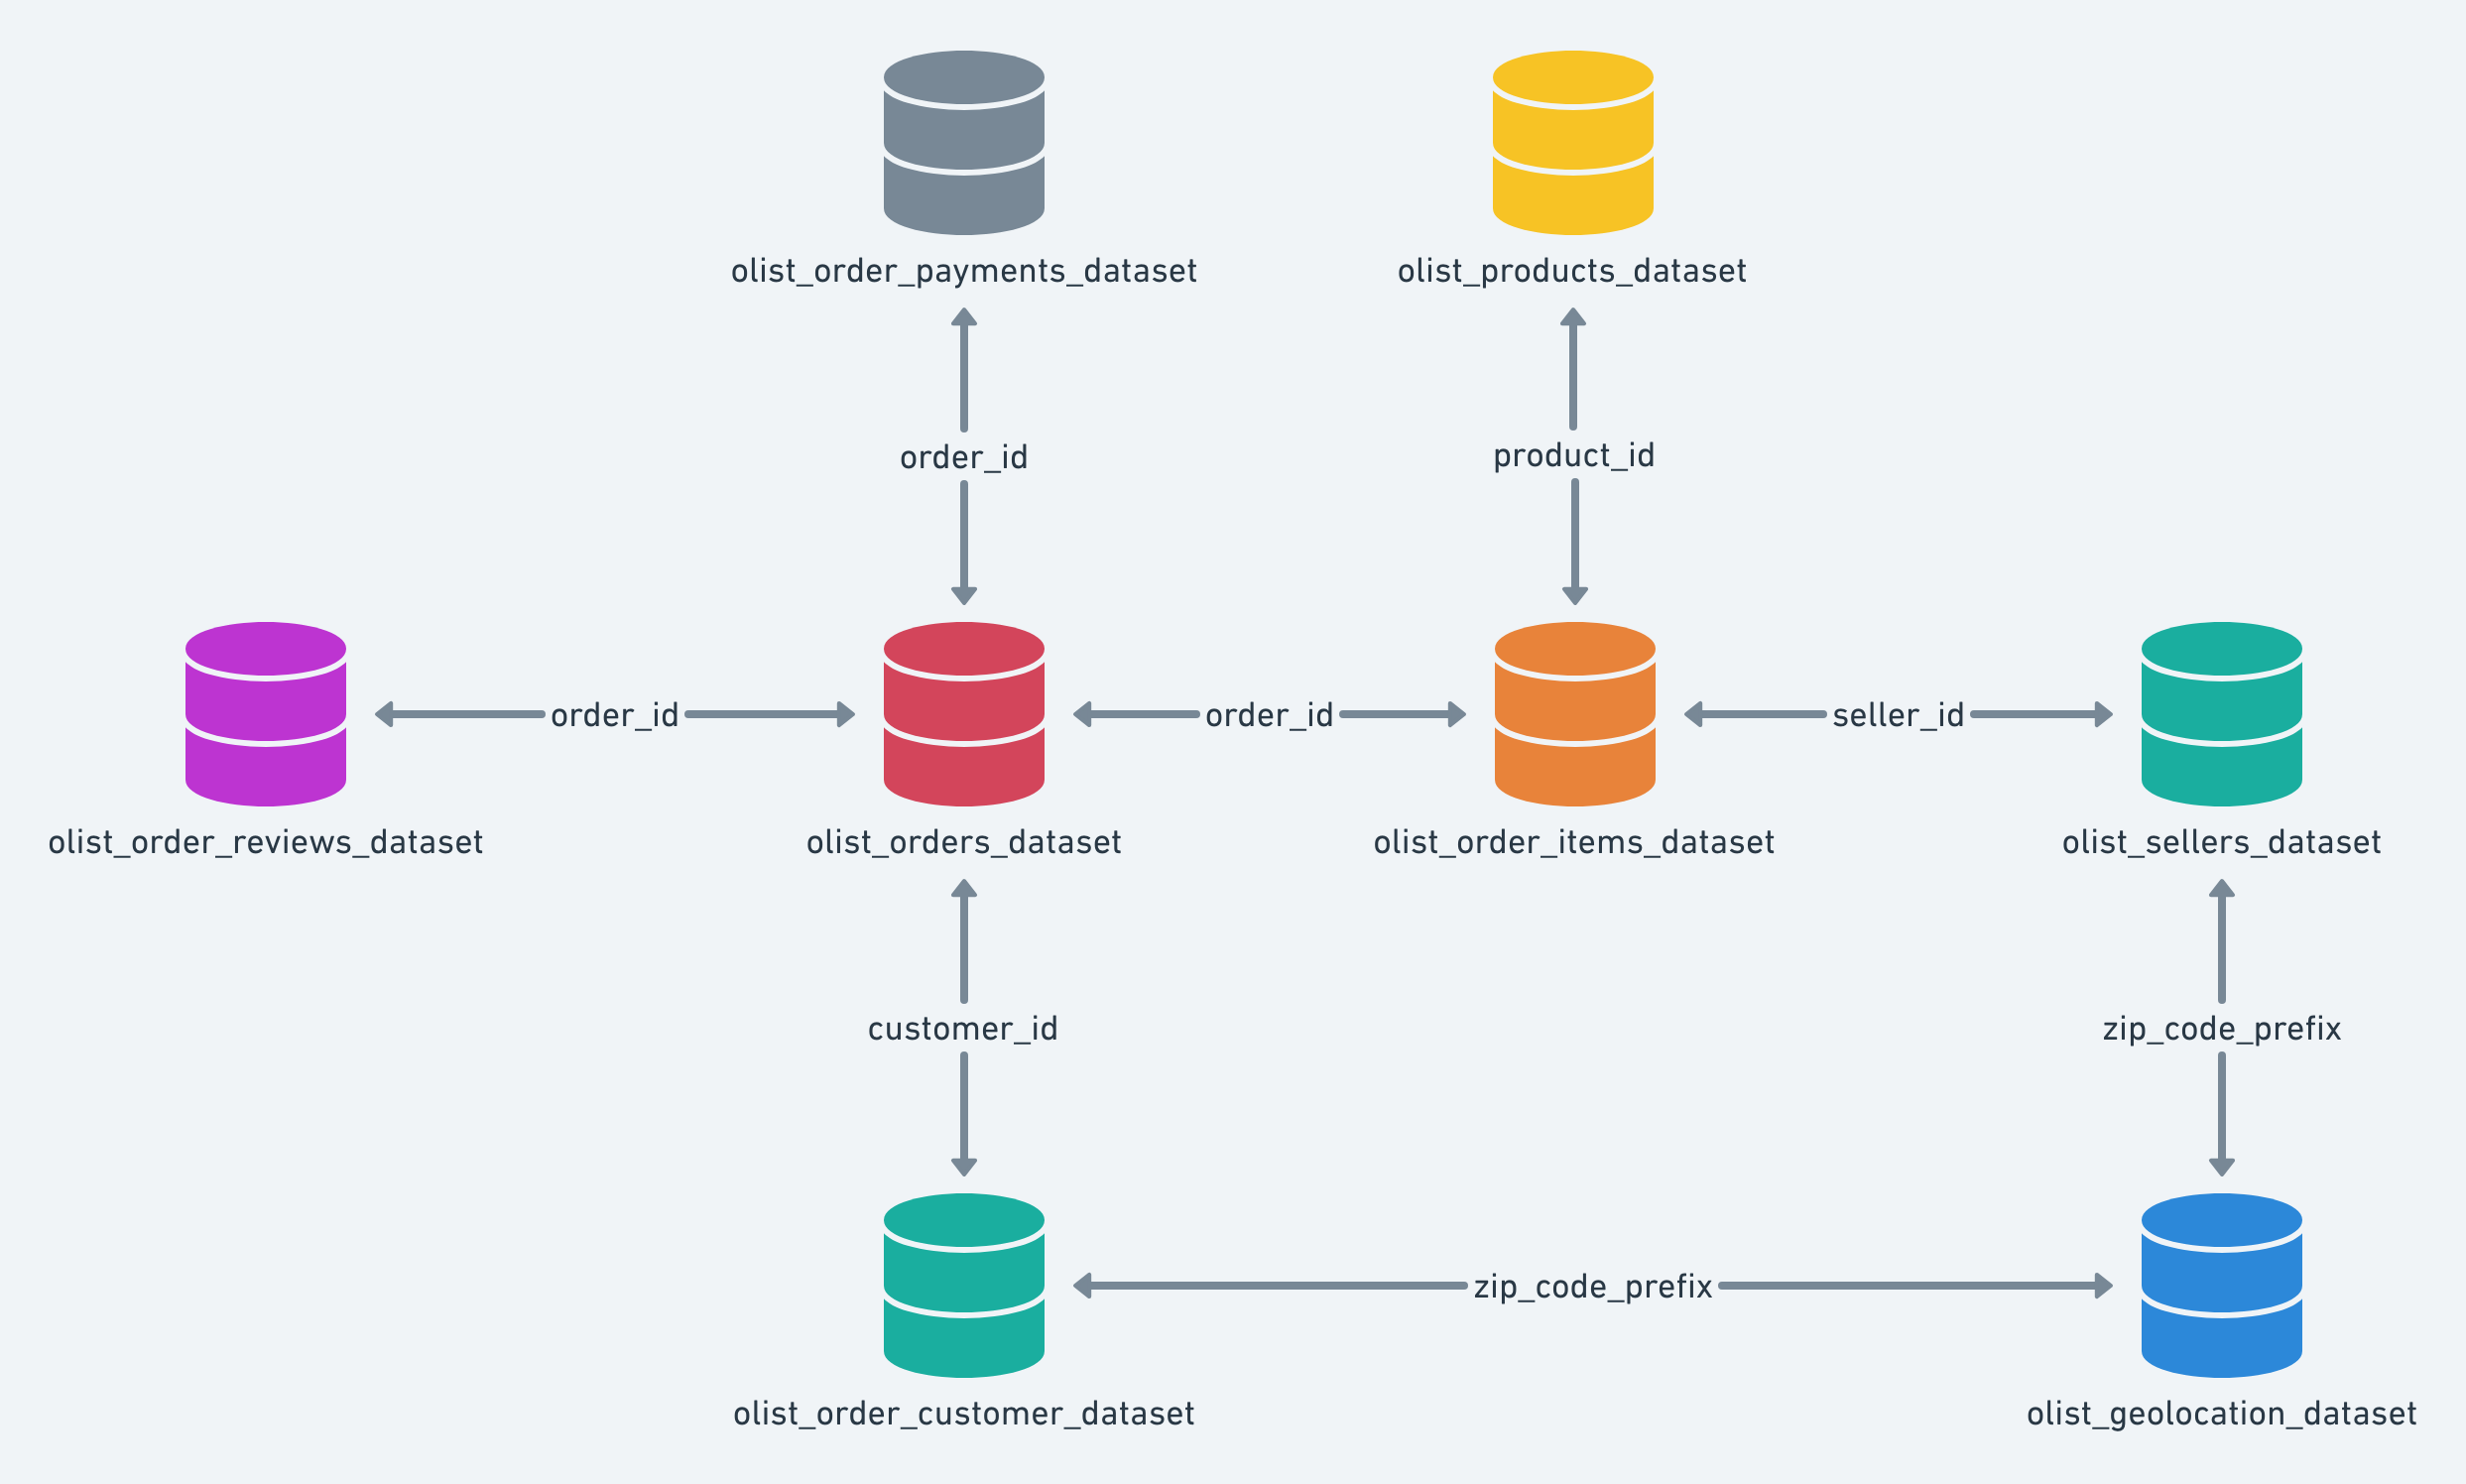

# Exemplo de análise: Boxplot de preços dos pedidos por ano de envio.

Arquivos necessários:
- olist_orders_dataset.csv
- olist_order_items_dataset.csv


Condições da análise:

- Pedidos com Status = Entregue
- Anos 2016--2018,

## Setup

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Carregar parte do dataset: Dois arquivos CSV

In [4]:
orders = pd.read_csv('olist_orders_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')

In [5]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

precisamos de order_status daqui

In [6]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')

precisamos de shipping_limit_date e price daqui

## Juntar as tabelas (merge)

Se eu tenho uma tabela de data de entrega, e outra de preço de produtos e fretes, podemos juntá-las pelo order_id

In [7]:
merged = pd.merge(orders, order_items, on='order_id')

In [8]:
merged.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value'],
      dtype='object')

## Filtrar apenas pelos pedidos entregues

E também cria uma cópia separada do dataframe

In [9]:
delivered = merged[merged['order_status'] == 'delivered'].copy()

In [10]:
len(delivered.index) #número de pedidos entregues

110197

## Obter informação dos anos de cada pedido

In [11]:
#https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
#https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.year.html

O tipo que a data é armazenada não é adequado

In [12]:
#delivered['shipping_limit_date']

Precisamos converter para datetime para extrair informações relevantes, como o ano

In [13]:
pd.to_datetime(delivered['shipping_limit_date']).dt.year

,shipping_limit_date
0,2017
1,2018
2,2018
3,2017
4,2018
...,...
112645,2018
112646,2017
112647,2018
112648,2018


Podemos criar uma nova coluna com os anos que foram extraídos

In [14]:
delivered['shipping_year'] = pd.to_datetime(delivered['shipping_limit_date']).dt.year

## Filtra por ano

In [15]:
delivered = delivered[delivered['shipping_year'].between(2016, 2018)]

## Box plot simples: Distribuição de preços por ano

Notar que os outliers foram omitidos para melhorar a visualização dos resultados.

Para mostrar os outliers, é só modificar o argumento do plot para:
showfliers=True

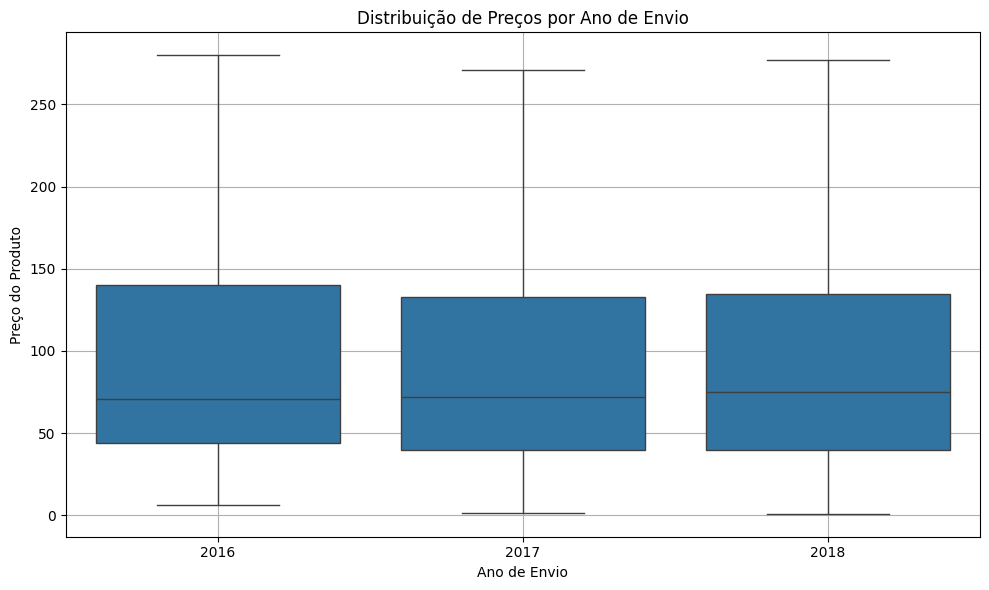

In [16]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=delivered, x='shipping_year', y='price', showfliers=False)

plt.title('Distribuição de Preços por Ano de Envio')
plt.ylabel('Preço do Produto')
plt.xlabel('Ano de Envio')
plt.grid(True)
plt.tight_layout()
plt.show()

# Questões

- Quantos pedidos foram realizados no período coberto pelo dataset?

Dica: utilizar o arquivo olist_orders_dataset.csv

In [17]:
total_pedidos = orders['order_id'].nunique()
print(f'Total de pedidos: {total_pedidos}')

Total de pedidos: 99441


- Qual foi a receita total gerada pela plataforma?

Dica: utilizar o arquivo olist_order_payments_dataset.csv, especialmente a coluna payment_value.

In [18]:
receita_total = payments['payment_value'].sum()
print(f'Receita total: R${receita_total:.2f}')

Receita total: R$16008872.12


- Qual é o valor médio por pedido (ticket médio = receita total dividida pelo número de pedidos)?

Dica: combinar olist_orders_dataset.csv com olist_order_payments_dataset.csv usando order_id.

In [19]:
orders_payments = pd.merge(
    orders,
    payments,
    on='order_id'
)

In [20]:
ticket_medio = receita_total / total_pedidos
print(f'Ticket médio: R${ticket_medio:.2f}')

Ticket médio: R$160.99


- Como o número de pedidos evoluiu ao longo do tempo?







Dica: utilizar a coluna order_purchase_timestamp do arquivo olist_orders_dataset.csv.

In [21]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

In [22]:
orders['years'] = orders['order_purchase_timestamp'].dt.year

In [23]:
pedidos_por_ano = orders.groupby('years')['order_id'].nunique()
pedidos_por_ano

,order_id
years,
2016,329
2017,45101
2018,54011


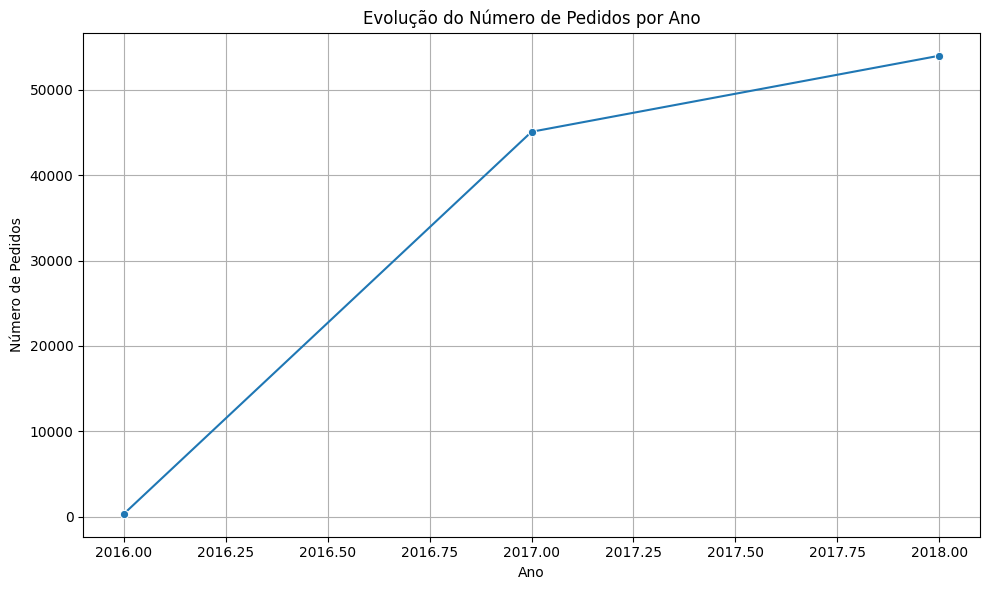

In [24]:
plt.figure(figsize=(10, 6))

sns.lineplot(x=pedidos_por_ano.index, y=pedidos_por_ano.values,marker='o')

plt.title('Evolução do Número de Pedidos por Ano')
plt.ylabel('Número de Pedidos')
plt.xlabel('Ano')
plt.grid(True)
plt.tight_layout()
plt.show()

O numero de pedidos aumentou significativamente entre 2016 e 2018, indicando um forte crescimento da quantidade de pedidos realizados na plataforma ao longo do periodo analisado

- Quais categorias geram maior receita?

Dica: combinar olist_order_items_dataset.csv com olist_products_dataset.csv e considerar a coluna price

In [25]:
items_products = pd.merge(
    order_items,
    products,
    on='product_id'
)

In [26]:
from numpy import sort
receita_categoria = (
    items_products
    .groupby('product_category_name')['price']
    .sum()
    .sort_values(ascending=False)
)
receita_categoria.head(10)

,price
product_category_name,
beleza_saude,1258681.34
relogios_presentes,1205005.68
cama_mesa_banho,1036988.68
esporte_lazer,988048.97
informatica_acessorios,911954.32
moveis_decoracao,729762.49
cool_stuff,635290.85
utilidades_domesticas,632248.66
automotivo,592720.11


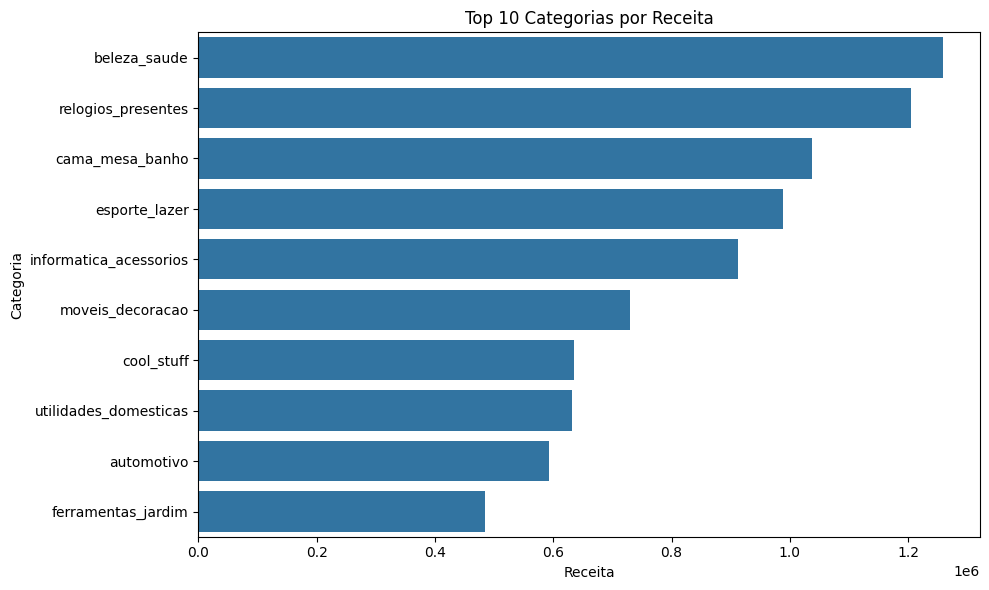

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=receita_categoria.head(10).values,
    y=receita_categoria.head(10).index
    )
plt.title("Top 10 Categorias por Receita")
plt.xlabel("Receita")
plt.ylabel("Categoria")
plt.tight_layout()
plt.show()

As categorias apresentam diferentes nivies de receita. O grafico permite identificar quais categorias concentram a maior parte da receita gerada pelas vendas de produtos

- Qual é o tempo médio entre a compra e a entrega do pedido?

Dica: utilizar olist_orders_dataset.csv, comparando order_purchase_timestamp e order_delivered_customer_date.

In [28]:
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])

delivered_orders = orders[orders['order_delivered_customer_date'].notna()].copy()

delivered_orders['order_purchase_timestamp'] = pd.to_datetime(delivered_orders['order_purchase_timestamp'])
delivered_orders['order_delivered_customer_date'] = pd.to_datetime(delivered_orders['order_delivered_customer_date'])

delivered_orders['delivery_days'] = (delivered_orders['order_delivered_customer_date'] - delivered_orders['order_purchase_timestamp']).dt.days

tempo_medio = delivered_orders['delivery_days'].mean()

print(f"Tempo médio entre compra e entrega: {tempo_medio:.2f} dias.")

Tempo médio entre compra e entrega: 12.09 dias.


O tempo medio calculado representa aproximadamente a quantidade de dias entre a realizacao da compra e a entrega ao cliente, considerando apenas os pedidos que possuem uma data de entrega registrada

- Quantos vendedores diferentes existem no dataset?

Dica: utilizar olist_sellers_dataset.csv.

In [29]:
total_vededores = sellers['seller_id'].nunique()
print(f'Total de vendedores: {total_vededores}')

Total de vendedores: 3095


- Distribuição de preços por tipos de produtos. Selecionar top 10 categorias por volume de vendas e fazer um gráfico com os box plots dessas 10 categorias, mostrando o preço (eixo y) em relação à categoria do produto (eixo x)

Dica: utilizar olist_order_items_dataset.csv e olist_products_dataset.csv

In [30]:
top_10_categorias = (
    items_products['product_category_name']
    .value_counts()
    .head(10)
)
top_10_categorias

,count
product_category_name,
cama_mesa_banho,11115
beleza_saude,9670
esporte_lazer,8641
moveis_decoracao,8334
informatica_acessorios,7827
utilidades_domesticas,6964
relogios_presentes,5991
telefonia,4545
ferramentas_jardim,4347


In [31]:
top_10_data = items_products[
    items_products['product_category_name'].isin(
        top_10_categorias.index
    )]

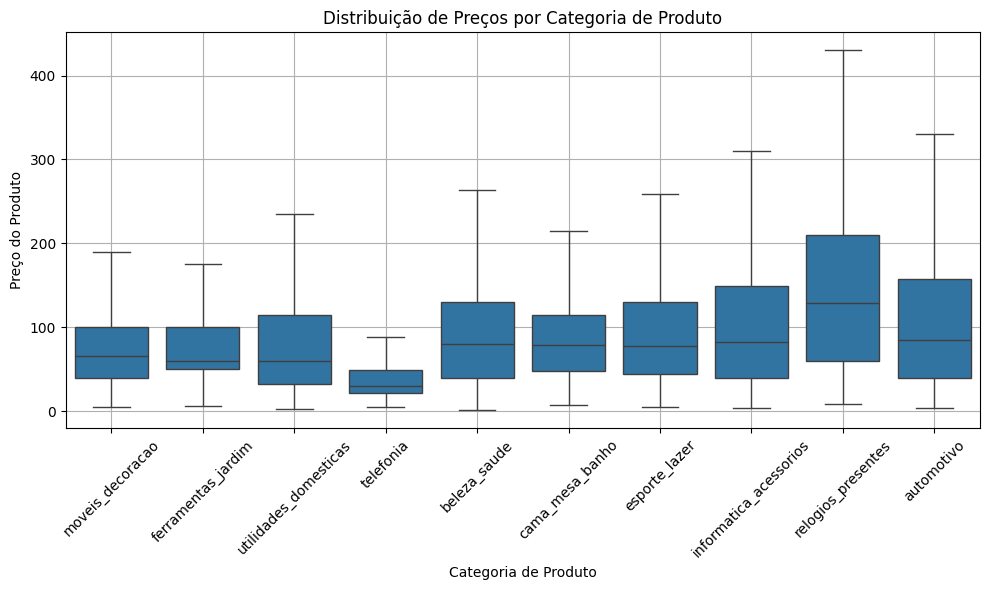

In [32]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=top_10_data, x='product_category_name', y='price' , showfliers=False)

plt.title('Distribuição de Preços por Categoria de Produto')
plt.ylabel('Preço do Produto')
plt.xlabel('Categoria de Produto')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

O boxplot permite comparar a distribuicao dos precos entre as 10 categorias com maior volume de vendas.É possivel observar diferencas entre as categorias em relacao a mediana, dispersao e valores extremos dos precos